# Прогнозирование сроков доставки Olist

## 1. Загрузка данных

In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'  # При необходимости укажите свое число физических ядер процессора

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

Path('results').mkdir(exist_ok=True)

folder = Path('data')
if not (folder / 'olist_orders_dataset.csv').exists():
    folder = Path.home() / 'ML_private_datasets' / 'olist'

orders = pd.read_csv(folder / 'olist_orders_dataset.csv', parse_dates=[
    'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'
])
customers = pd.read_csv(folder / 'olist_customers_dataset.csv')
items = pd.read_csv(folder / 'olist_order_items_dataset.csv')

print('Заказы:', len(orders))
print('Покупатели:', len(customers))
print('Товары:', len(items))

Заказы: 99441
Покупатели: 99441
Товары: 112650


## 2. Дубликаты и пропуски

In [2]:
for name, table in [('Заказы', orders), ('Покупатели', customers), ('Товары', items)]:
    print(name)
    print('Дубликаты строк:', table.duplicated().sum())
    print('Пропуски:', table.isna().sum()[lambda s: s > 0].to_dict())

print('Повторения order_id в товарах:', items['order_id'].duplicated().sum())

Заказы
Дубликаты строк: 0
Пропуски: {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
Покупатели
Дубликаты строк: 0
Пропуски: {}
Товары
Дубликаты строк: 0
Пропуски: {}
Повторения order_id в товарах: 13984


Пропуски: {}
Товары


Дубликаты строк: 0
Пропуски: {}
Повторения order_id в товарах: 13984


## 3. Объединение таблиц

In [3]:
items = items.groupby('order_id', as_index=False)[['price', 'freight_value']].sum()

df = orders[orders['order_status'] == 'delivered'].copy()
df = df.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
df = df.merge(items, on='order_id', how='left')

print('Заказов после объединения:', len(df))
print('Повторы order_id:', df['order_id'].duplicated().sum())

Заказов после объединения: 96478
Повторы order_id: 0


## 4. Цель, признаки и очистка

In [4]:
df['delivery_days'] = (
    df['order_delivered_customer_date'] - df['order_purchase_timestamp']
).dt.total_seconds() / 86400

df['estimated_days'] = (
    df['order_estimated_delivery_date'] - df['order_purchase_timestamp']
).dt.total_seconds() / 86400

num_cols = ['estimated_days', 'price', 'freight_value']
cat_cols = ['customer_state']
features = num_cols + cat_cols

print('Пропуски после объединения:')
print(df[features + ['delivery_days']].isna().sum())

df = df.dropna(subset=['delivery_days', 'order_purchase_timestamp'])
df = df[df['delivery_days'] >= 0].copy()
print('Заказов после очистки:', len(df))

Пропуски после объединения:
estimated_days    0
price             0
freight_value     0
customer_state    0
delivery_days     8
dtype: int64
Заказов после очистки: 96470


## 5. Train / Test, короткая статистика

In [5]:
df = df.sort_values('order_purchase_timestamp')
X = df[features]
y = df['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)
print('Train:', len(X_train), 'Test:', len(X_test))

Train: 77176 Test: 19294


count    77176.00
mean        13.51
std         10.03
min          0.53
25%          7.22
50%         11.18
75%         16.97
max        209.63
Name: delivery_days, dtype: float64


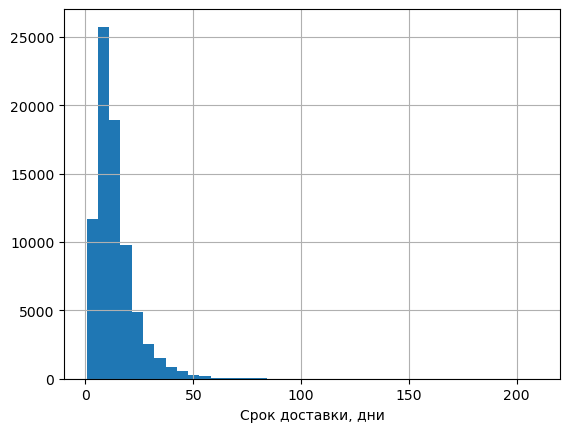

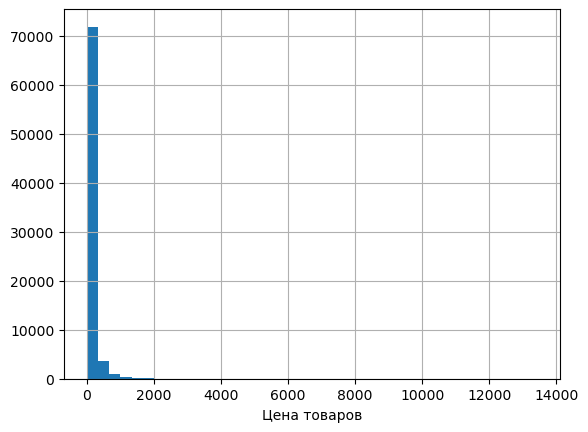

In [6]:
print(y_train.describe().round(2))
y_train.hist(bins=40)
plt.xlabel('Срок доставки, дни')
plt.savefig('results/delivery_hist.png')
plt.show()

X_train['price'].hist(bins=40)
plt.xlabel('Цена товаров')
plt.savefig('results/price_hist.png')
plt.show()

## 6. Предобработка

In [7]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## 7. Сравнение моделей (CV)

In [8]:
models = {
    'Median': DummyRegressor(strategy='median'),
    'Ridge': Ridge(alpha=10),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=40, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=150, loss='absolute_error', random_state=42),
    'CatBoost': CatBoostRegressor(iterations=250, depth=6, learning_rate=0.08, loss_function='MAE', random_seed=42, verbose=False, allow_writing_files=False)
}

cv = TimeSeriesSplit(n_splits=3)
scores = []

for name, model in models.items():
    errors = []
    for train_idx, val_idx in cv.split(X_train):
        X_tr = preprocessor.fit_transform(X_train.iloc[train_idx])
        X_val = preprocessor.transform(X_train.iloc[val_idx])
        model.fit(X_tr, y_train.iloc[train_idx])
        pred = model.predict(X_val)
        errors.append(mean_absolute_error(y_train.iloc[val_idx], pred))
    scores.append([name, np.mean(errors)])

results = pd.DataFrame(scores, columns=['Model', 'MAE']).sort_values('MAE')
print(results.round(3).to_string(index=False))
results.round(3).to_csv('results/validation_results.csv', index=False)

            Model   MAE
         CatBoost 5.626
    Random Forest 5.627
Gradient Boosting 5.634
            Ridge 5.663
    Decision Tree 5.725
           Median 6.841


## 8. График сравнения

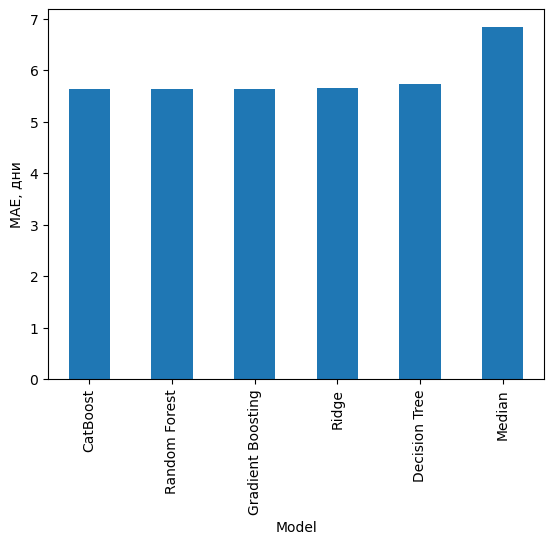

In [9]:
results.plot.bar(x='Model', y='MAE', legend=False)
plt.ylabel('MAE, дни')
plt.savefig('results/validation_mae.png')
plt.show()

## 9. Итоговая проверка на Test

In [10]:
best_name = results.iloc[0]['Model']
best_model = models[best_name]

X_tr = preprocessor.fit_transform(X_train)
X_te = preprocessor.transform(X_test)
best_model.fit(X_tr, y_train)
y_pred = best_model.predict(X_te)
median_pred = np.full(len(y_test), y_train.median())

test_results = pd.DataFrame({
    'Model': ['Median', best_name],
    'MAE': [mean_absolute_error(y_test, median_pred), mean_absolute_error(y_test, y_pred)]
})

print('Лучшая модель:', best_name)
print(test_results.round(3).to_string(index=False))
test_results.round(3).to_csv('results/test_results.csv', index=False)

Лучшая модель: CatBoost
   Model   MAE
  Median 4.963
CatBoost 3.982


## 10. Факт и прогноз

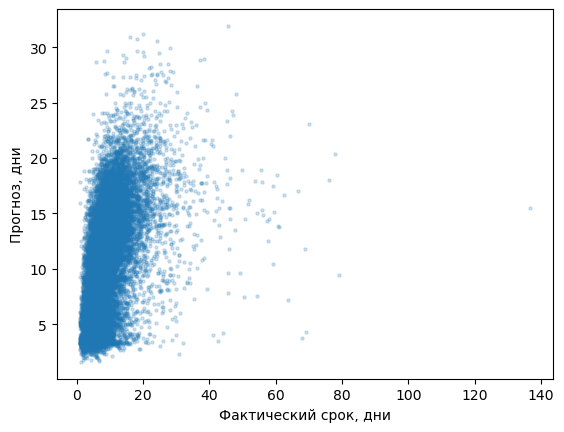

In [11]:
plt.scatter(y_test, y_pred, s=5, alpha=0.2)
plt.xlabel('Фактический срок, дни')
plt.ylabel('Прогноз, дни')
plt.savefig('results/test_predictions.png')
plt.show()

## Вывод

Модели сравниваются с медианным прогнозом на временной кросс-валидации. Обработку пропусков и масштабирование обучаем отдельно на каждом тренировочном блоке. Тестовая выборка используется один раз для итоговой оценки. Прогноз рассчитан только для доставленных заказов.